
# Obesity Level Prediction Using Machine Learning

**Course:** DS471 – Machine Learning

**Project Objective:** This project aims to predict obesity levels using eating habits and physical characteristics. Three machine-learning models will be developed and compared: Logistic Regression, Random Forest, and a Neural Network.


## Stage 1: Data Cleaning, Preparation and Exploration

### Dataset Description

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")

# Display dataset information
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Data Quality Checks

We examine the dataset to identify missing values, duplicate records, inconsistent data, and data types. We also check the distribution of obesity levels before preparing the data for machine learning.

In [2]:
# Check the dataset structure and data types
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check target class distribution
print("\nObesity level distribution:")
print(df["NObeyesdad"].value_counts())

# Check categorical values for inconsistencies
print("\nCategorical feature values:")
for column in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF          


### Duplicate and Data Consistency Analysis

The dataset contains 24 exact duplicate records and no missing values. Before removing duplicates, we check whether identical feature values have different obesity-level labels.


In [3]:

# Check whether identical features have conflicting labels
feature_columns = df.columns.drop("NObeyesdad")

conflicting_labels = (
    df.groupby(list(feature_columns), dropna=False)["NObeyesdad"]
    .nunique()
)

print("Feature combinations with conflicting labels:",
      (conflicting_labels > 1).sum())

print("Exact duplicate rows:", df.duplicated().sum())


Feature combinations with conflicting labels: 0
Exact duplicate rows: 24



### Duplicate Removal

The dataset contains 24 exact duplicate records. No conflicting class labels were found for identical feature values. Therefore, we remove the duplicate records before splitting the data to prevent repeated observations from affecting model evaluation.


In [4]:

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Verify the results
print("Dataset shape after cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())


Dataset shape after cleaning: (2087, 17)
Remaining duplicates: 0



### Outlier Detection

We use the Interquartile Range (IQR) method to identify possible outliers in the numerical features. These values will be examined before deciding whether any changes are necessary.


In [5]:

# Identify possible outliers using the IQR method
numeric_columns = df.select_dtypes(include="number").columns

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[numeric_columns] < (Q1 - 1.5 * IQR)) |
    (df[numeric_columns] > (Q3 + 1.5 * IQR))
)

print("Possible outliers by feature:")
print(outliers.sum().sort_values(ascending=False))


Possible outliers by feature:
NCP       577
Age       167
Weight      1
Height      1
FCVC        0
CH2O        0
FAF         0
TUE         0
dtype: int64



### Outlier Handling

The IQR method identified 577 possible outliers in NCP, 167 in Age, and one each in Height and Weight. However, these values are not necessarily incorrect. NCP represents meal frequency, while differences in age, height, and weight may reflect natural variation between individuals.

Therefore, no records were removed based only on the IQR results. The observations are retained to avoid losing potentially useful information for predicting obesity levels.



### Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns and relationships in the dataset. We begin by examining the distribution of the seven obesity levels.


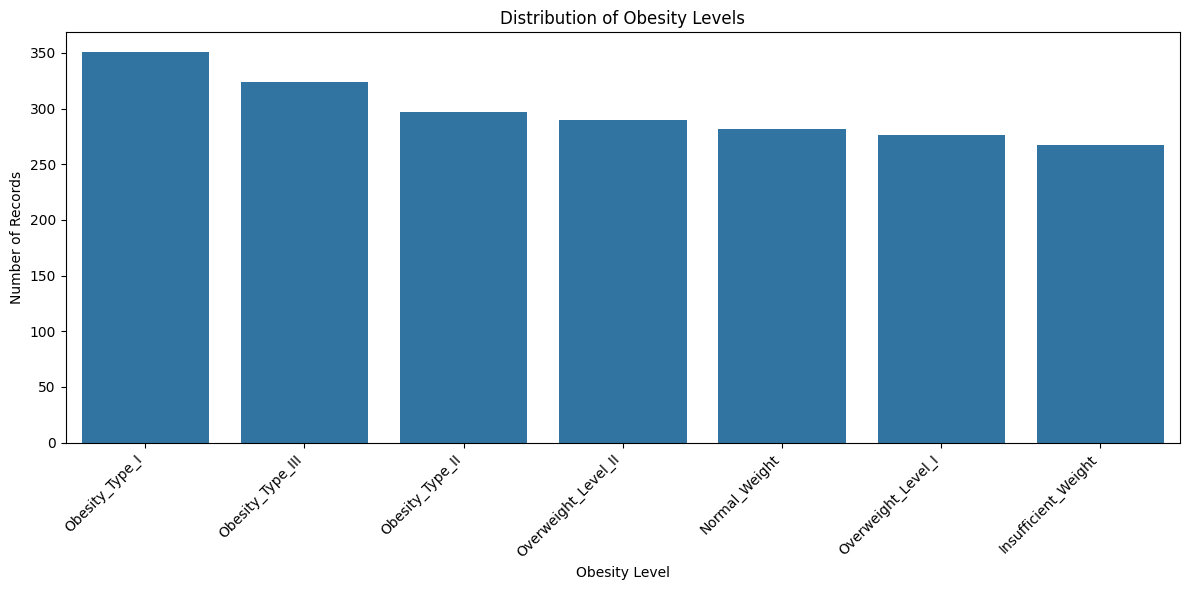

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Display the distribution of obesity levels
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="NObeyesdad",
    order=df["NObeyesdad"].value_counts().index
)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### Class Distribution Analysis

The chart shows that the seven obesity categories have relatively similar numbers of records. Obesity_Type_I has the largest number of samples, while Insufficient_Weight has the smallest. Overall, there is no severe class imbalance.

We will use stratified data splitting to preserve the proportion of each obesity category in the training, validation, and test sets. Accuracy and macro-averaged F1-score will be used to compare model performance across all seven classes.



### Feature Correlation Analysis

We examine the relationships between numerical features using a correlation heatmap. This helps us identify strongly related measurements and understand possible patterns in the dataset.


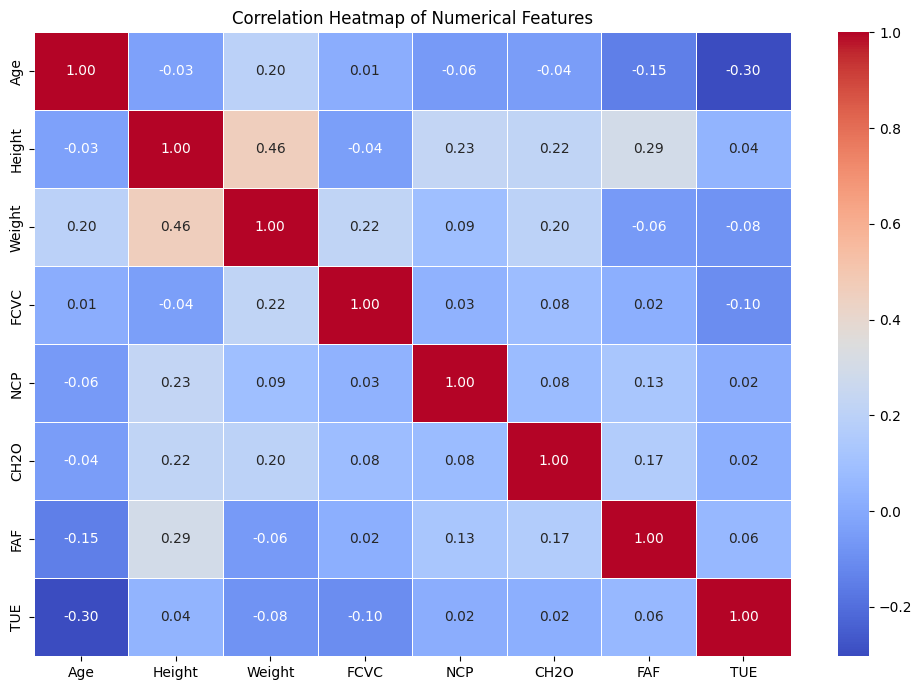

In [7]:

# Select numerical features for correlation analysis
numeric_features = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_features.corr()

# Display the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



### Correlation Analysis Results

The correlation heatmap shows that most numerical features have weak relationships with each other. Height and Weight have the strongest positive correlation (0.46), while Age and TUE have a negative correlation (-0.30).

These findings suggest that most numerical features provide different information. Therefore, no features will be removed based only on this correlation analysis. Feature relevance will be examined further during model development.



### Feature Distribution Analysis

We use histograms to examine the distributions of numerical features in the Obesity dataset. These graphs help us understand how the values vary and identify possible patterns or skewness.


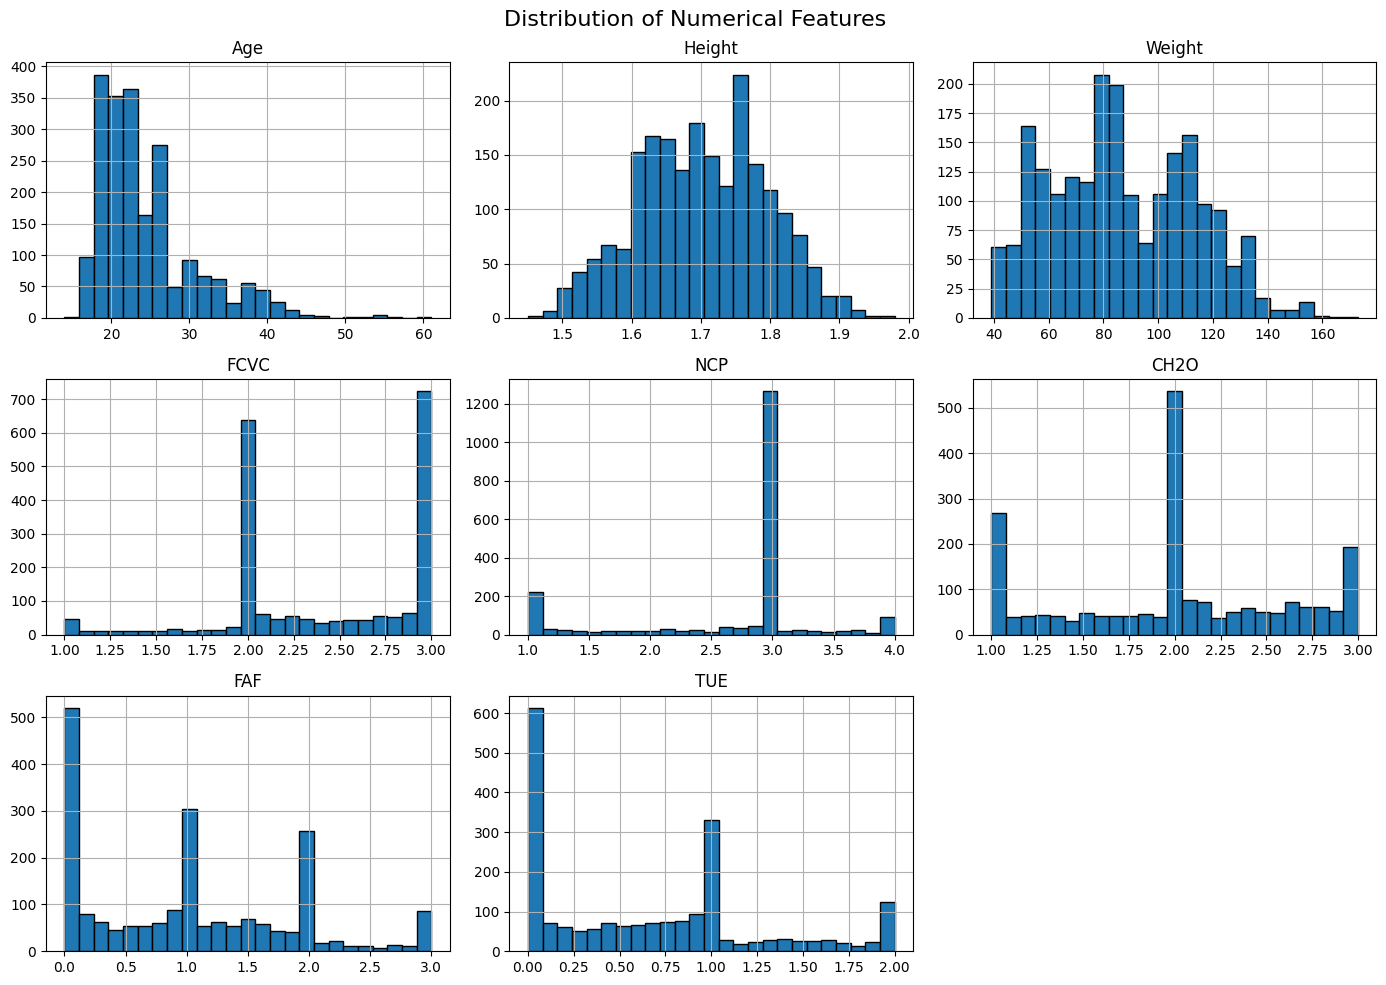

In [8]:

import matplotlib.pyplot as plt

# Select numerical features
numeric_features = df.select_dtypes(include="number")

# Plot numerical feature distributions
numeric_features.hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()



### Feature Distribution Results

The histograms show different patterns across the numerical features. Age is concentrated among younger adults, while Height is distributed around the middle of its range. Weight has a wider distribution with several peaks.

FCVC, NCP, and CH2O show concentrations at specific values. FAF has noticeable peaks near 0, 1, and 2, while TUE is concentrated mainly around 0 and 1.

These patterns show that the features have different ranges and distributions. Appropriate encoding and scaling will be applied during model development, with data-dependent preprocessing fitted on the training data only.



### Feature Relevance Analysis

We examine how numerical features differ across the seven obesity categories. This helps us understand which measurements may be useful for prediction. Final feature selection, if needed, will use training data only to prevent data leakage.


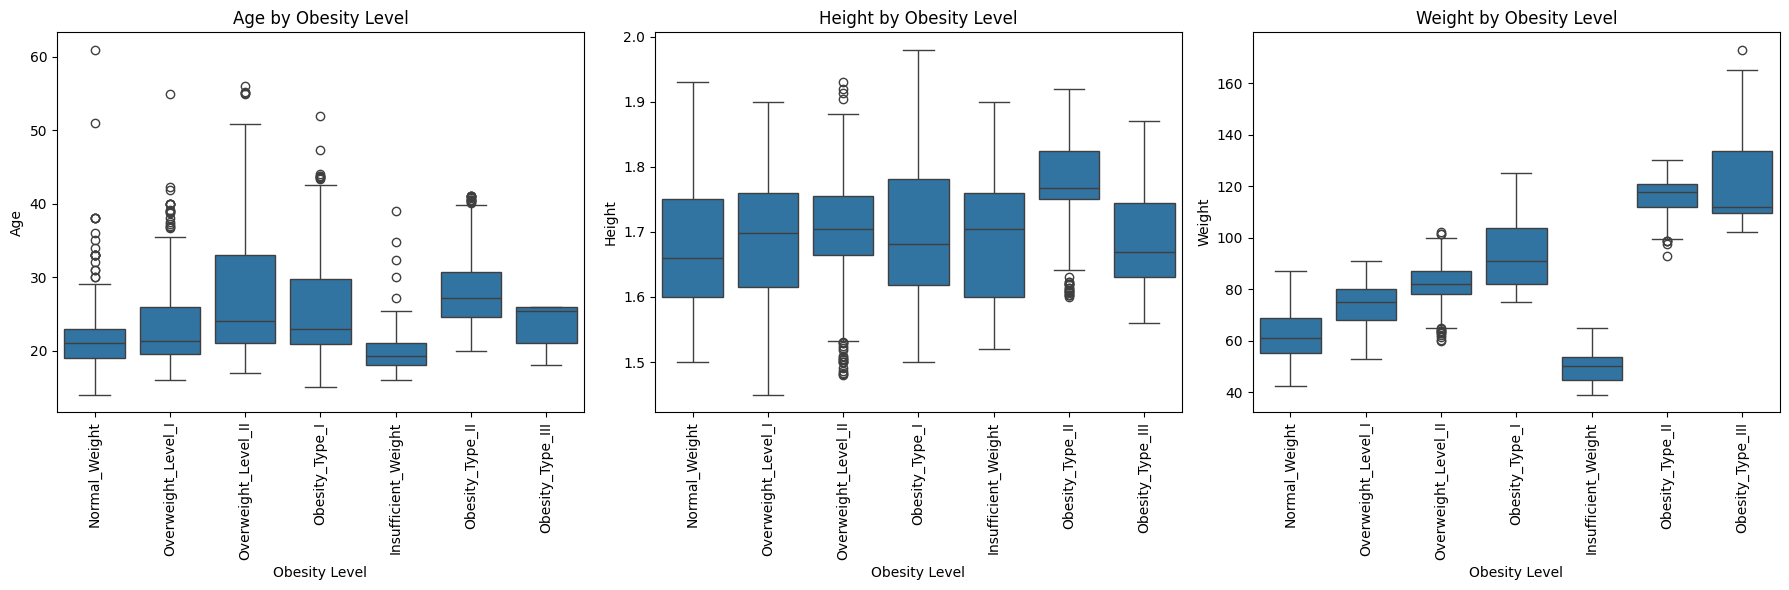

In [9]:

# Compare numerical features across obesity levels
features_to_examine = ["Age", "Height", "Weight"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, feature in enumerate(features_to_examine):
    sns.boxplot(
        data=df,
        x="NObeyesdad",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} by Obesity Level")
    axes[i].tick_params(axis="x", rotation=90)
    axes[i].set_xlabel("Obesity Level")

plt.tight_layout()
plt.show()



### Feature Relevance Results

The boxplots show how Age, Height, and Weight vary across the seven obesity categories. Age and Height have overlapping distributions, meaning these features alone may not clearly distinguish the classes. Weight shows clearer differences between categories and appears particularly useful for predicting obesity levels.

Since obesity categories are closely related to body measurements, especially height and weight, these relationships should be considered when interpreting model performance.

These plots provide an initial understanding of feature relevance. All features will be retained for initial model development, while any data-dependent feature selection will use training data only.



### Feature Engineering

The dataset contains 16 features related to eating habits, physical activity, and personal characteristics. We will keep the original features because they provide useful information for predicting obesity levels.

No additional features will be created at this stage. In particular, BMI will not be added because obesity categories are already closely related to height and weight.



### Encoding

The dataset contains numerical and categorical features. One-Hot Encoding will be used to convert categorical features into numerical values so they can be processed by the machine-learning models.

The target variable, NObeyesdad, contains seven obesity categories. Label Encoding will be used to convert these class names into numerical labels from 0 to 6.

Categorical feature encoding will be fitted using the training data only to prevent data leakage.



### Scaling

The numerical features have different ranges. StandardScaler will be used to standardize these features for Logistic Regression and the Neural Network.

Random Forest does not require feature scaling, so it can use the original numerical values.

Scaling will be fitted only on the training data. The same fitted transformation will then be applied to the validation and test sets.



## Stage 2: Data Splitting

The cleaned dataset is divided into 70% training, 15% validation, and 15% testing data. This ratio provides enough records for model training while keeping separate datasets for validation and final evaluation.

Stratified splitting is used to maintain similar proportions of the seven obesity categories in each set. A fixed random state is used to make the results reproducible.


In [10]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["NObeyesdad"])
y = df["NObeyesdad"]

# Split into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Divide temporary data into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the dataset sizes
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

# Verify that all seven classes are represented
print("\nNumber of classes in each set:")
print("Training:", y_train.nunique())
print("Validation:", y_val.nunique())
print("Testing:", y_test.nunique())


Training set: (1460, 16)
Validation set: (313, 16)
Test set: (314, 16)

Number of classes in each set:
Training: 7
Validation: 7
Testing: 7



### Data Splitting Results

After removing 24 duplicate records, the dataset contains 2,087 records. The data was divided into 1,460 training records, 313 validation records, and 314 test records.

A 70% training, 15% validation, and 15% testing ratio was selected to provide sufficient data for learning while keeping separate datasets for model development and final evaluation.

Stratified splitting was used to maintain the proportions of the seven obesity categories. All seven classes are represented in each dataset.

The training set will be used to fit the models, the validation set will be used to monitor and compare their performance, and the test set will be reserved for final evaluation.
